In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

In [2]:
# Load training and testing datasets
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

# Check dataset sizes
print("Training data:", train.shape)
print("Testing data:", test.shape)

train.head()

Training data: (1349, 14)
Testing data: (338, 14)


,chembl_id,pref_name,smiles,molecular_weight,logp,hba,hbd,psa,rtb,ro5_violations,aromatic_rings,heavy_atoms,pf_ec50_uM,pf_pEC50
0,CHEMBL600904,NaN,Oc1c2c(nc3cc(-c4ccccc4)nn13)CCCC2,265.32,2.98,4.0,1.0,50.42,1.0,0.0,3.0,20.0,1.7415,5.759077
1,CHEMBL3477295,NaN,Cc1cccnc1[C@H](C)Nc1nc(-c2cccnc2)nc2c1CNC2,332.41,3.02,6.0,2.0,75.62,4.0,0.0,3.0,25.0,1.0546,5.976912
2,CHEMBL603037,NaN,O=C(c1ccccc1)N1CCN(c2ccccc2NC(=O)C(Cl)(Cl)Cl)CC1,426.73,3.96,3.0,1.0,52.65,3.0,0.0,2.0,27.0,1.4457,5.839922
3,CHEMBL3504689,NaN,Cc1ncc(CN(Cc2ccccn2)Cc2ccccc2Cl)n1C.O=C(O)CC(O...,532.98,3.98,4.0,0.0,33.95,6.0,0.0,3.0,24.0,0.5040,6.297569
4,CHEMBL3404024,NaN,Cc1ccc([C@H]2N[C@H](C(=O)O)Cc3c2[nH]c2ccccc32)...,320.39,3.47,2.0,3.0,65.12,2.0,0.0,3.0,24.0,10.0000,5.000000


In [3]:
# Create Morgan fingerprint generator
generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=1024
)

# Function to convert SMILES into fingerprints
def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return generator.GetFingerprintAsNumPy(mol)

# Generate fingerprints
train_fps = [smiles_to_fingerprint(s) for s in train["smiles"]]
test_fps = [smiles_to_fingerprint(s) for s in test["smiles"]]

# Check for invalid structures
print("Invalid training structures:", sum(fp is None for fp in train_fps))
print("Invalid testing structures:", sum(fp is None for fp in test_fps))

Invalid training structures: 0
Invalid testing structures: 0


In [4]:
# Convert fingerprints into NumPy arrays
X_train_fp = np.array(train_fps)
X_test_fp = np.array(test_fps)

# Select the target values
y_train = train["pf_pEC50"]
y_test = test["pf_pEC50"]

# Check the shapes
print("Training fingerprints:", X_train_fp.shape)
print("Testing fingerprints:", X_test_fp.shape)

Training fingerprints: (1349, 1024)
Testing fingerprints: (338, 1024)


In [5]:
# Create SVR model
svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.1)
)

# Evaluate using 5-fold cross-validation
svr_cv_scores = cross_val_score(
    svr_model,
    X_train_fp,
    y_train,
    cv=5,
    scoring="r2"
)

print("SVR CV R² scores:", svr_cv_scores.round(4))
print("Mean SVR CV R²:", round(svr_cv_scores.mean(), 4))

SVR CV R² scores: [ 0.1999  0.2103  0.157  -0.0156  0.0708]
Mean SVR CV R²: 0.1245


In [6]:
# Select the 9 molecular descriptors
features = [
    "molecular_weight",
    "logp",
    "hba",
    "hbd",
    "psa",
    "rtb",
    "ro5_violations",
    "aromatic_rings",
    "heavy_atoms"
]

# Combine fingerprints with molecular descriptors
X_train_combined = np.hstack((
    X_train_fp,
    train[features].to_numpy()
))

X_test_combined = np.hstack((
    X_test_fp,
    test[features].to_numpy()
))

# Create SVR model
svr_combined = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=0.1)
)

# Evaluate using 5-fold cross-validation
combined_cv_scores = cross_val_score(
    svr_combined,
    X_train_combined,
    y_train,
    cv=5,
    scoring="r2"
)

print("Combined SVR CV R² scores:", combined_cv_scores.round(4))
print("Mean combined SVR CV R²:", round(combined_cv_scores.mean(), 4))

Combined SVR CV R² scores: [ 0.2042  0.2135  0.1619 -0.0126  0.0761]
Mean combined SVR CV R²: 0.1286


In [7]:
# Create SVR pipeline
svr_pipeline = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

# Settings to test
param_grid = {
    "svr__C": [0.1, 1, 10, 100],
    "svr__gamma": ["scale", 0.001, 0.01],
    "svr__epsilon": [0.1, 0.2]
}

# Find the best settings using cross-validation
svr_grid = GridSearchCV(
    svr_pipeline,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

svr_grid.fit(X_train_combined, y_train)

print("Best parameters:", svr_grid.best_params_)
print("Best CV R²:", round(svr_grid.best_score_, 4))

Best parameters: {'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma': 0.001}
Best CV R²: 0.1578


In [8]:
# Get the best SVR model
best_svr = svr_grid.best_estimator_

# Predict training values
svr_train_predictions = best_svr.predict(X_train_combined)

# Calculate training performance
svr_train_r2 = r2_score(y_train, svr_train_predictions)
svr_train_rmse = np.sqrt(mean_squared_error(y_train, svr_train_predictions))

print("SVR Training R²:", round(svr_train_r2, 4))
print("SVR Training RMSE:", round(svr_train_rmse, 4))
print("SVR Mean CV R²:", round(svr_grid.best_score_, 4))

SVR Training R²: 0.82
SVR Training RMSE: 0.2348
SVR Mean CV R²: 0.1578


In [9]:
# Create SVR using the best settings
best_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=1, epsilon=0.1, gamma=0.001)
)

# Train the model
best_svr.fit(X_train_combined, y_train)

print("SVR trained successfully!")

SVR trained successfully!


In [10]:
# Predict test values
svr_test_predictions = best_svr.predict(X_test_combined)

# Calculate performance
svr_test_r2 = r2_score(y_test, svr_test_predictions)
svr_test_rmse = np.sqrt(mean_squared_error(y_test, svr_test_predictions))

print("Final SVR Results")
print("-----------------")
print(f"Test R²: {svr_test_r2:.4f}")
print(f"Test RMSE: {svr_test_rmse:.4f}")

Final SVR Results
-----------------
Test R²: 0.1209
Test RMSE: 0.5467


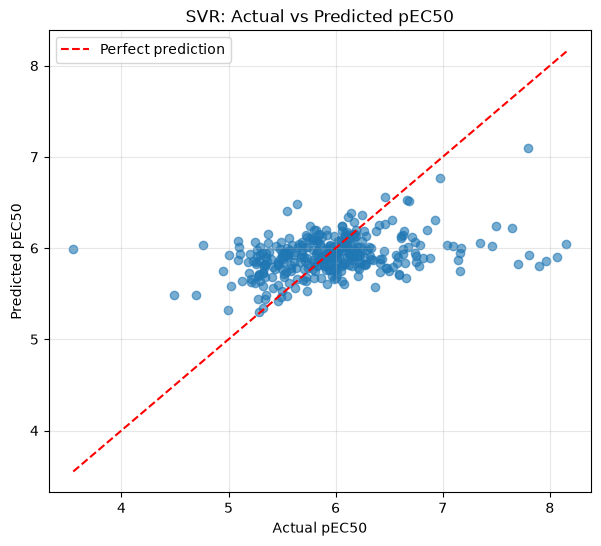

In [11]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, svr_test_predictions, alpha=0.6)

minimum = min(y_test.min(), svr_test_predictions.min())
maximum = max(y_test.max(), svr_test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual pEC50")
plt.ylabel("Predicted pEC50")
plt.title("SVR: Actual vs Predicted pEC50")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

The SVR model achieved a test R² of 0.1209 and RMSE of 0.5467. Similar to Random Forest, predictions were concentrated around pEC50 6, with low activity values generally overestimated and high activity values underestimated. This suggests that SVR also struggled to predict compounds with extreme antiparasitic activity.

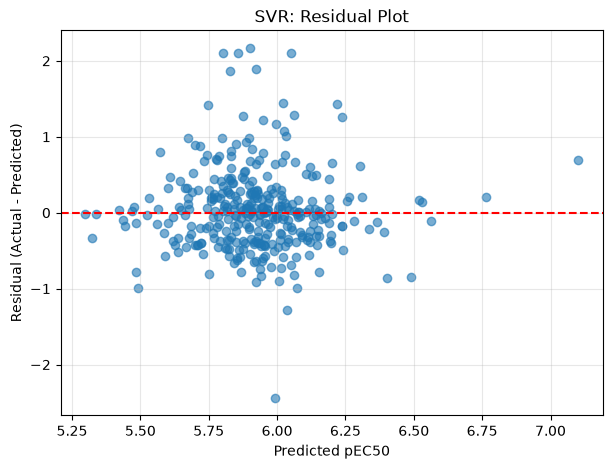

In [12]:
# Calculate residuals
residuals = y_test - svr_test_predictions

plt.figure(figsize=(7, 5))

plt.scatter(svr_test_predictions, residuals, alpha=0.6)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted pEC50")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("SVR: Residual Plot")

plt.grid(alpha=0.3)
plt.show()

The SVR residual plot shows that most prediction errors are concentrated near zero, although several large residuals are present. The model produces both overestimations and underestimations, with some errors exceeding 2 pEC50 units. Combined with the actual-versus-predicted graph, this suggests that SVR struggles to predict compounds with extreme activity values.